# Pricing Test: Paired vs. Independent, and the Regression-to-the-Mean Trap

A business raised prices 3% at a set of locations. Did revenue actually go up?

All data is simulated (see `generate_data.py`), so the true effect is known and each method can be checked against it:
- **Part A:** the price increase lifts revenue about 2.5%.
- **Part B:** the price increase does nothing (true effect = 0), but the client picked locations that just had a bad summer.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

part_a = pd.read_csv("data/locations_before_after.csv")
part_b = pd.read_csv("data/location_periods.csv")
part_a.head()

,location_id,revenue_before,revenue_after
0,L01,159310.0,163420.0
1,L02,99000.0,102810.0
2,L03,174550.0,179890.0
3,L04,145530.0,147660.0
4,L05,36950.0,38040.0


## Part A: Is the revenue increase statistically significant?

12 locations, average weekly revenue for the 8 weeks before and after the price increase.

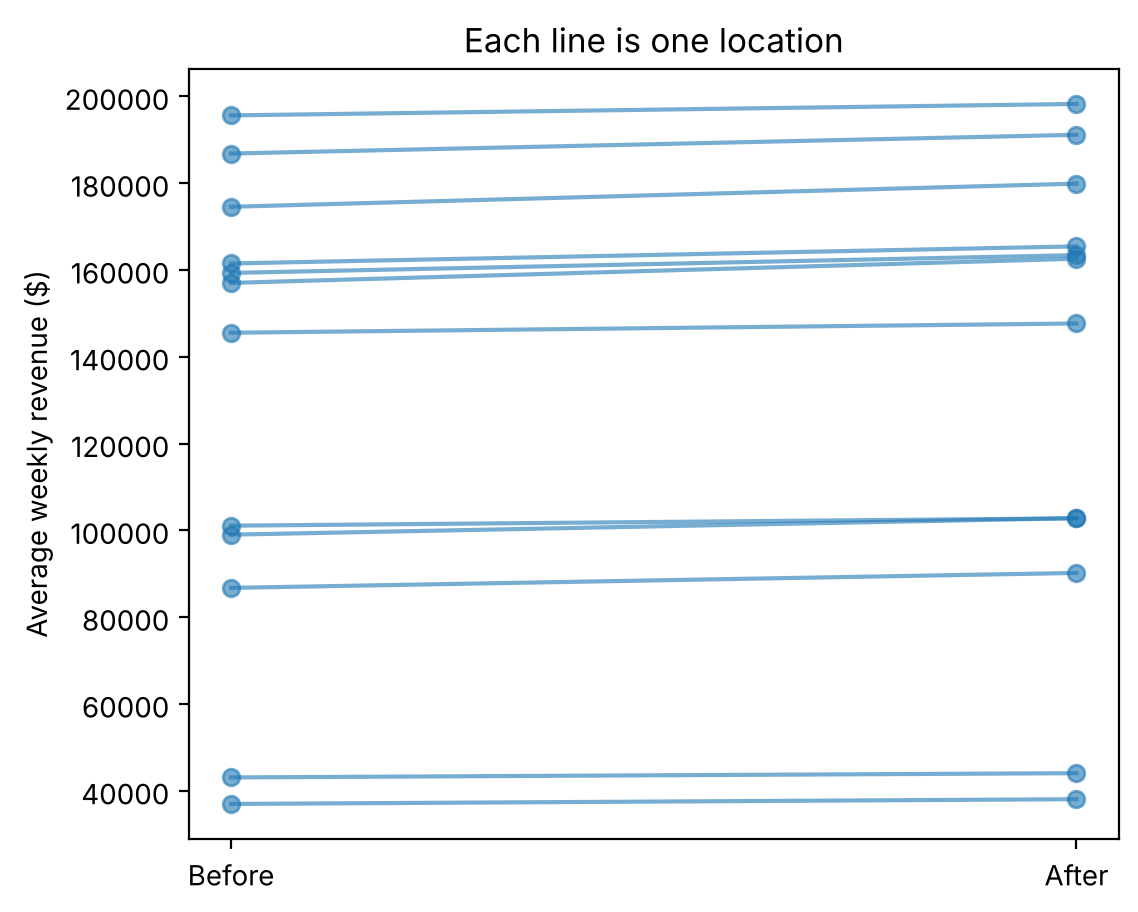

,revenue_before,revenue_after,change,pct_change
count,12.0,12.0,12.0,12.0
mean,128928.3,132185.0,3256.7,2.6
std,54114.2,55174.3,1547.9,0.9
min,36950.0,38040.0,980.0,1.3
25%,95935.0,99622.5,2022.5,2.1
50%,151270.0,155125.0,3625.0,2.5
75%,164755.0,169045.0,4162.5,3.2
max,195610.0,198250.0,5580.0,4.0


In [2]:
part_a["change"] = part_a["revenue_after"] - part_a["revenue_before"]
part_a["pct_change"] = part_a["change"] / part_a["revenue_before"] * 100

fig, ax = plt.subplots(figsize=(6, 5))
for _, row in part_a.iterrows():
    ax.plot([0, 1], [row["revenue_before"], row["revenue_after"]], marker="o", color="tab:blue", alpha=0.6)
ax.set_xticks([0, 1], ["Before", "After"])
ax.set_ylabel("Average weekly revenue ($)")
ax.set_title("Each line is one location")
plt.show()

part_a[["revenue_before", "revenue_after", "change", "pct_change"]].describe().round(1)

### Step 1: Independent two-sample t-test (the wrong test)

Treats "before" and "after" as two unrelated groups of locations.

In [3]:
ind = stats.ttest_ind(part_a["revenue_after"], part_a["revenue_before"])
print(f"Independent t-test: t = {ind.statistic:.2f}, p = {ind.pvalue:.3f}")

Independent t-test: t = 0.15, p = 0.885


### Step 2: Paired t-test, Wilcoxon signed-rank, and a 95% confidence interval (the right tests)

Each location is measured twice, so the test should look at each location's own change.

In [4]:
diff = part_a["revenue_after"] - part_a["revenue_before"]

paired = stats.ttest_rel(part_a["revenue_after"], part_a["revenue_before"])
wilcoxon = stats.wilcoxon(part_a["revenue_after"], part_a["revenue_before"])
ci_low, ci_high = stats.t.interval(0.95, len(diff) - 1, loc=diff.mean(), scale=stats.sem(diff))

pct = part_a["pct_change"]
pct_low, pct_high = stats.t.interval(0.95, len(pct) - 1, loc=pct.mean(), scale=stats.sem(pct))

print(f"Paired t-test:        t = {paired.statistic:.2f}, p = {paired.pvalue:.6f}")
print(f"Wilcoxon signed-rank: W = {wilcoxon.statistic:.0f}, p = {wilcoxon.pvalue:.5f}")
print(f"Locations that went up: {(diff > 0).sum()} of {len(diff)}")
print(f"Mean change: ${diff.mean():,.0f} per location (95% CI ${ci_low:,.0f} to ${ci_high:,.0f})")
print(f"Mean % change: {pct.mean():.2f}% (95% CI {pct_low:.2f}% to {pct_high:.2f}%)")
print()
print(f"Spread of revenue BETWEEN locations (SD): ${part_a['revenue_before'].std():,.0f}")
print(f"Spread of each location's CHANGE (SD):    ${diff.std():,.0f}")

Paired t-test:        t = 7.29, p = 0.000016
Wilcoxon signed-rank: W = 0, p = 0.00049
Locations that went up: 12 of 12
Mean change: $3,257 per location (95% CI $2,273 to $4,240)
Mean % change: 2.62% (95% CI 2.06% to 3.18%)

Spread of revenue BETWEEN locations (SD): $54,114
Spread of each location's CHANGE (SD):    $1,548


### Why the two tests disagree

The independent test compares the average of all "before" numbers with the average of all "after" numbers. Those averages are buried in a huge amount of variation between locations: the biggest location does about five times the revenue of the smallest (standard deviation of about \$54,000), so a \$3,000 shift looks like noise and the test returns p = 0.89.

The paired test only looks at how much each location changed. The size differences cancel out, and what's left is very consistent: all 12 locations went up, with a standard deviation of only about \$1,500 in the change. That gives p < 0.0001, and the Wilcoxon test (which doesn't assume the changes are normally distributed) agrees.

**The paired test is the right one** because the same 12 locations were measured twice. Its estimate, about +2.6% per location (95% CI 2.1% to 3.2%), lines up with the true effect of 2.5% built into the simulation.

## Part B: The client picked its weakest locations

New scenario. 60 locations. The client gave the price increase to the **12 locations whose summer was weakest compared with their own 2-year average**. The increase started in the fall. **In this simulation the price increase has no effect at all.**

Columns:
- `revenue_trailing_2yr_avg`: each location's normal weekly revenue
- `revenue_summer`: the period used to pick locations
- `revenue_fall`: after the price increase
- `price_increase`: True for the 12 picked locations

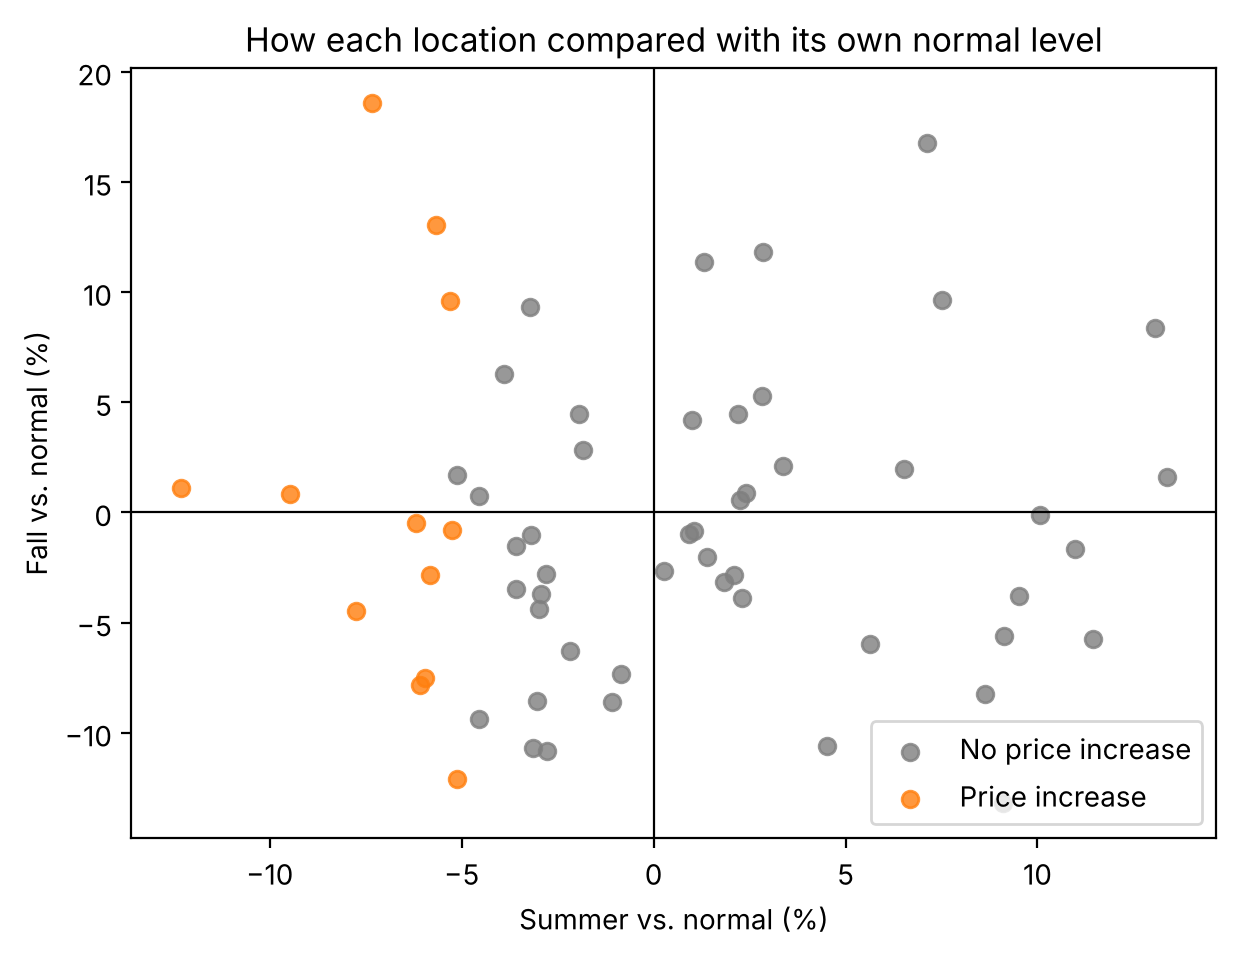

In [5]:
part_b["summer_vs_normal_pct"] = (part_b["revenue_summer"] / part_b["revenue_trailing_2yr_avg"] - 1) * 100
part_b["fall_vs_normal_pct"] = (part_b["revenue_fall"] / part_b["revenue_trailing_2yr_avg"] - 1) * 100

fig, ax = plt.subplots(figsize=(7, 5))
for treated, color, label in [(False, "tab:gray", "No price increase"), (True, "tab:orange", "Price increase")]:
    d = part_b[part_b["price_increase"] == treated]
    ax.scatter(d["summer_vs_normal_pct"], d["fall_vs_normal_pct"], color=color, label=label, alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Summer vs. normal (%)")
ax.set_ylabel("Fall vs. normal (%)")
ax.set_title("How each location compared with its own normal level")
ax.legend(loc="lower right")
plt.show()

In [6]:
treated = part_b[part_b["price_increase"]]
control = part_b[~part_b["price_increase"]]

def pct_change(df, start, end):
    """Aggregate % change in total revenue between two columns."""
    return (df[end].sum() / df[start].sum() - 1) * 100

### Step 4: Naive before/after (summer to fall, price-increase locations only)

In [7]:
naive = pct_change(treated, "revenue_summer", "revenue_fall")
naive_test = stats.ttest_rel(treated["revenue_fall"], treated["revenue_summer"])
print(f"Summer to fall, price-increase locations: {naive:+.2f}%  (paired t-test p = {naive_test.pvalue:.3f})")

Summer to fall, price-increase locations: +7.41%  (paired t-test p = 0.015)


### Step 5: Compare against locations without the increase (difference-in-differences)

In [8]:
control_change = pct_change(control, "revenue_summer", "revenue_fall")
did = naive - control_change
print(f"Price-increase locations: {naive:+.2f}%")
print(f"Other 48 locations:       {control_change:+.2f}%")
print(f"Difference-in-differences: {did:+.2f} percentage points")

Price-increase locations: +7.41%
Other 48 locations:       -3.29%
Difference-in-differences: +10.70 percentage points


### Step 6: Compare against each location's own normal level

In [9]:
treated_vs_normal = pct_change(treated, "revenue_trailing_2yr_avg", "revenue_fall")
control_vs_normal = pct_change(control, "revenue_trailing_2yr_avg", "revenue_fall")
baseline_est = treated_vs_normal - control_vs_normal
summer_dip = pct_change(treated, "revenue_trailing_2yr_avg", "revenue_summer")

per_loc_test = stats.ttest_ind(treated["fall_vs_normal_pct"], control["fall_vs_normal_pct"], equal_var=False)
print(f"Price-increase locations in summer vs. normal: {summer_dip:+.2f}%  (why they were picked)")
print(f"Price-increase locations in fall vs. normal:   {treated_vs_normal:+.2f}%")
print(f"Other locations in fall vs. normal:            {control_vs_normal:+.2f}%")
print(f"Estimated effect: {baseline_est:+.2f} points  (Welch t-test on per-location % vs. normal: p = {per_loc_test.pvalue:.2f})")

Price-increase locations in summer vs. normal: -6.89%  (why they were picked)
Price-increase locations in fall vs. normal:   +0.01%
Other locations in fall vs. normal:            -1.17%
Estimated effect: +1.17 points  (Welch t-test on per-location % vs. normal: p = 0.59)


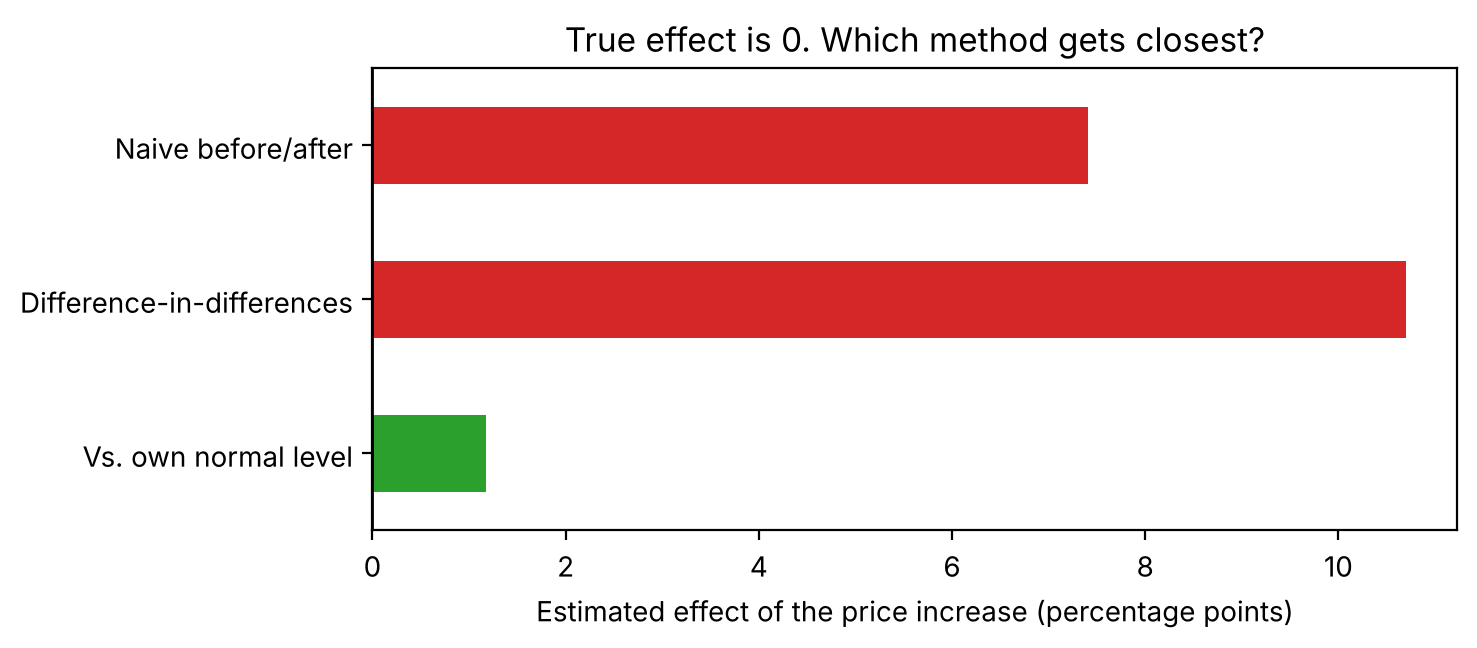

,method,estimated effect (pts),true effect (pts)
0,Naive before/after,7.41,0.0
1,Difference-in-differences,10.70,0.0
2,Vs. own normal level,1.17,0.0


In [10]:
results = pd.DataFrame({
    "method": ["Naive before/after", "Difference-in-differences", "Vs. own normal level"],
    "estimated effect (pts)": [naive, did, baseline_est],
})
results["true effect (pts)"] = 0.0
ax = results.plot.barh(x="method", y="estimated effect (pts)", legend=False, color=["tab:red", "tab:red", "tab:green"], figsize=(7, 3))
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Estimated effect of the price increase (percentage points)")
ax.set_ylabel("")
ax.set_title("True effect is 0. Which method gets closest?")
ax.invert_yaxis()
plt.show()
results.round(2)

### Step 7: Which method got it right?

**Only the comparison against each location's own normal level got close to the truth** (about +1 point, not statistically significant, versus a true effect of 0).

- **The naive before/after said +7.4%, with p = 0.015.** That looks like a clear win, but the 12 locations were picked *because* their summer was unusually bad (about 7% below normal). Bad stretches are partly random, so they tend to bounce back on their own. That's regression to the mean, and it produced the whole "lift."
- **Difference-in-differences made it worse (+10.7 points).** The comparison group isn't neutral: by leaving out the 12 worst summers, it's left with locations that had average-to-good summers, and those drifted *down* in the fall (−3.3%). Subtracting a downward drift from an upward bounce inflates the estimate. Difference-in-differences assumes both groups would have moved the same way without the price change, and selecting on a bad period breaks that assumption.
- **Comparing with each location's long-run average works** because the 2-year average wasn't used to pick locations, so it isn't distorted by the bad summer.

**What I'd tell the client:** the before/after number can't go in a deck as the effect of the price increase. The locations were chosen for a bad stretch, so a rebound was expected anyway. Measured against their own normal levels, there's no clear evidence the price increase changed revenue.

### Step 8: Give the price increase a real effect

Rebuild Part B with a true effect of +3% and rerun all three methods.

In [11]:
import generate_data as gen

def rerun_part_b(true_effect: float) -> pd.Series:
    gen.TRUE_PRICE_EFFECT_B = true_effect
    rng = np.random.default_rng(gen.SEED)
    gen.make_part_a(rng)            # keep the random sequence identical to the original run
    b = gen.make_part_b(rng)
    t, c = b[b["price_increase"]], b[~b["price_increase"]]
    naive = pct_change(t, "revenue_summer", "revenue_fall")
    return pd.Series({
        "Naive before/after": naive,
        "Difference-in-differences": naive - pct_change(c, "revenue_summer", "revenue_fall"),
        "Vs. own normal level": pct_change(t, "revenue_trailing_2yr_avg", "revenue_fall")
                                - pct_change(c, "revenue_trailing_2yr_avg", "revenue_fall"),
    })

pd.DataFrame({"true effect 0%": rerun_part_b(0.0), "true effect 3%": rerun_part_b(0.03)}).round(2)

,true effect 0%,true effect 3%
Naive before/after,7.41,10.63
Difference-in-differences,10.70,13.92
Vs. own normal level,1.17,4.17


With a real +3% effect, the baseline comparison lands near 3% (about 4 points; with only 12 locations, some noise is expected). The naive method and difference-in-differences overshoot by 7 to 11 points, the same bias as before stacked on top of the real effect.

## Takeaways

- **Match the test to the design.** The same locations measured twice means paired data. The independent test missed a real, consistent +2.6% effect (p = 0.89 vs. p < 0.0001).
- **Ask how the locations were chosen before trusting a before/after number.** Picking locations because they had a bad stretch builds in a rebound. Here it created a "significant" +7.4% out of nothing.
- **A comparison group only helps if it's comparable.** Difference-in-differences against locations that weren't selected for a bad period made the bias bigger, not smaller. A baseline that wasn't used for selection (each location's own long-run average) got close to the truth.